# Прогноз цены подержанного автомобиля

Эксперимент на двух исходных выборках CarDekho. Цена указана в индийских рупиях (₹), пробег — в километрах. Для повторного запуска откройте ноутбук из корня репозитория в окружении Python 3.12 с пакетами из `requirements-notebook.txt`. Исходные CSV лежат в `data/`. После **Run All** обновятся HTML-профиль и файл модели для приложения.

# **Домашнее задание №1 PRO**

В этом домашнем задании вам будет необходимо:
*  обучить модель регрессии для предсказания стоимости автомобилей;


**Оценивание**

Максимальная оценка за ДЗ — **10 баллов**:
- Части 1–5 (EDA, модели, категориальные признаки, Feature Engineering, бизнес-метрика) — 5 баллов;
- Часть 6, оформление репозитория — 2 балла;
- Часть 7, Streamlit-приложение — 3 балла.

**Дедлайн: 2 декабря**

**Примечание**

В каждой части оцениваются как код, **так и ответы на вопросы.**

Если нет одного и/или другого, то часть баллов за соответствующее задание снимается.

Все зависимости зафиксированы в репозитории. Команда установки — `python -m pip install -r requirements-notebook.txt`.

In [1]:
import pickle
import random
import warnings
from itertools import combinations
from pathlib import Path

warnings.filterwarnings("ignore", message=r".*IProgress not found.*")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
# В отчёте используется ydata-profiling, указанная в задании.
warnings.filterwarnings("ignore", message=r"(?s).*import ydata_profiling.*deprecated.*", category=DeprecationWarning)
import phik
import seaborn as sns
from IPython.display import IFrame, Markdown, display
from sklearn.base import clone
from sklearn.compose import TransformedTargetRegressor
from sklearn.dummy import DummyRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import ElasticNet, Lasso, LinearRegression, Ridge
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import GridSearchCV, KFold
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler
from ydata_profiling import ProfileReport

from car_features import (
    CATEGORIES, NUMERIC, RAW_COLUMNS, TARGET, clean_measurements,
    feature_frame, make_preprocessor, model_coefficients, parse_torque,
)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
cv = KFold(n_splits=10, shuffle=True, random_state=SEED)
# Для новой категории с drop="first" sklearn кодирует блок нулями.
warnings.filterwarnings("ignore", message="Found unknown categories.*", category=UserWarning)
%matplotlib inline
sns.set_theme(style="whitegrid", context="notebook", palette="colorblind")
pd.options.display.float_format = "{:,.3f}".format

### **Задание 0**
Давайте зафиксируем важный момент.

**Задание 0 (0 баллов).**
Изучите и ответьте на вопрос: для чего фиксируем сиды в домашках?

Фиксация начального состояния генераторов позволяет повторить разбиение на фолды и сравнить эксперименты на одних и тех же объектах. Для воспроизводимости также нужны те же данные, версии библиотек и порядок вычислений. Фиксированный seed сам по себе не устраняет смещение выборки.

# **Часть 1 | EDA**


Первая часть состоит из классических шагов EDA:

- Базовый EDA и обработка признаков (1.4 балла)
- Визуализации признаков и их анализ (0.9 балла)

Всего за эту часть можно набрать 2.3 балла.

## **Простейший EDA и обработка признаков (1.4 балла)**

In [2]:
raw_train = pd.read_csv("data/cars_train.csv")
raw_test = pd.read_csv("data/cars_test.csv")
df_train, df_test = raw_train.copy(), raw_test.copy()
print("Train", df_train.shape, "· Test", df_test.shape)
display(df_train.head(3))

Train (6999, 13) · Test (1000, 13)


,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats
0,Maruti Swift Dzire VDI,2014,450000,145500,Diesel,Individual,Manual,First Owner,23.4 kmpl,1248 CC,74 bhp,190Nm@ 2000rpm,5.000
1,Skoda Rapid 1.5 TDI Ambition,2014,370000,120000,Diesel,Individual,Manual,Second Owner,21.14 kmpl,1498 CC,103.52 bhp,250Nm@ 1500-2500rpm,5.000
2,Hyundai i20 Sportz Diesel,2010,225000,127000,Diesel,Individual,Manual,First Owner,23.0 kmpl,1396 CC,90 bhp,22.4 kgm at 1750-2750rpm,5.000


### **Задание 1 (0.4 балла)**
Выполните операции, направленные на базовое исследование данных:

- [x] Посмотрите, есть ли в датасете пропуски. Запишите/выведите названия колонок, для которых есть пропущенные значения (0.1 балла)
- [x] Посмотрите, есть ли в данных явные дубликаты (0.05 балла)
- [x] Постройте дашборд в одну строку, используя [ydata-profiling](https://github.com/ydataai/ydata-profiling) (0.1 балла)
- [x] Опишите базовые выводы (какие — выберите сами), используя дашборд (0.15 балла).

In [3]:
nulls = pd.concat([df_train.isna().sum(), df_test.isna().sum()], axis=1, keys=["train", "test"])
display(nulls.loc[nulls.any(axis=1)])

,train,test
mileage,202,19
engine,202,19
max_power,196,19
torque,203,19
seats,202,19


Пропуски затрагивают пять столбцов технических характеристик. У большинства строк с пропусками отсутствует сразу несколько параметров, поэтому удаление таких строк меняло бы состав выборки.

In [4]:
for name, data in [("train", df_train), ("test", df_test)]:
    print(f"{name}: {data.duplicated().sum()} полных дублей сверх первого экземпляра, "
          f"{data.isna().any(axis=1).sum()} строк с пропусками")

train: 985 полных дублей сверх первого экземпляра, 203 строк с пропусками
test: 62 полных дублей сверх первого экземпляра, 19 строк с пропусками


In [5]:
profile = ProfileReport(df_train, title="CarDekho · профиль исходного train", minimal=True, progress_bar=False, pool_size=1)
report_path = Path("reports/train_profile.html")
report_path.parent.mkdir(exist_ok=True)
profile.to_file(report_path)
display(IFrame(src=report_path.as_posix(), width="100%", height=520))

В профиле train 13 столбцов и 1 924 различных названия комплектаций. У 6 095 из 6 999 автомобилей механическая коробка, 5 826 объявлений разместили частные продавцы. Цена достигает 10 млн ₹ при медиане 450 тыс. ₹. Редкие дорогие машины сильно влияют на квадратичную ошибку. Полный HTML-файл можно открыть в браузере из папки `reports/`.

### **Задание 2 (0.2 балла)**
Проанализируйте статистики датасета.

**Ваша задача:**
- [x] Посчитайте основные статистики по числовым столбцам для трейна и теста
- [x] Посчитайте основные статистики по категориальным столбцам для трейна и теста
- [x] Сравните среднее и медиану внутри `train`, внутри `test` и между собой. О чём могут говорить результаты?
- [x] Сделайте выводы по статистикам. Отсутствие выводов равносильно по баллам невыполнению задания.

**Подсказка:**

Используйте ``.describe()`` с нужным(и) аргументом(-ами).

In [6]:
for name, data in [("train", df_train), ("test", df_test)]:
    display(Markdown(f"**{name} · числовые столбцы**"), data.describe().T)
    display(Markdown(f"**{name} · строковые столбцы**"), data.describe(include="object").T)
display(pd.concat(
    {name: data.select_dtypes("number").agg(["mean", "median"]).T
     for name, data in [("train", df_train), ("test", df_test)]}, axis=1
))

**train · числовые столбцы**

,count,mean,std,min,25%,50%,75%,max
year,"6,999.000","2,013.818",4.053,"1,983.000","2,011.000","2,015.000","2,017.000","2,020.000"
selling_price,"6,999.000","639,515.197","808,941.912","29,999.000","254,999.000","450,000.000","675,000.000","10,000,000.000"
km_driven,"6,999.000","69,584.616","57,724.002",1.000,"35,000.000","60,000.000","97,000.000","2,360,457.000"
seats,"6,797.000",5.419,0.966,2.000,5.000,5.000,5.000,14.000


**train · строковые столбцы**

,count,unique,top,freq
name,6999,1924,Maruti Swift Dzire VDI,116
fuel,6999,4,Diesel,3793
seller_type,6999,3,Individual,5826
transmission,6999,2,Manual,6095
owner,6999,5,First Owner,4587
mileage,6797,386,18.9 kmpl,197
engine,6797,120,1248 CC,885
max_power,6803,316,74 bhp,330
torque,6796,419,190Nm@ 2000rpm,468


**test · числовые столбцы**

,count,mean,std,min,25%,50%,75%,max
year,"1,000.000","2,013.681",4.012,"1,995.000","2,011.000","2,014.000","2,017.000","2,020.000"
selling_price,"1,000.000","617,901.042","758,553.861","31,000.000","250,000.000","434,999.000","670,000.000","6,000,000.000"
km_driven,"1,000.000","71,393.341","48,486.219","1,303.000","37,000.000","61,500.000","100,000.000","375,000.000"
seats,981.000,5.411,0.920,4.000,5.000,5.000,5.000,9.000


**test · строковые столбцы**

,count,unique,top,freq
name,1000,621,Maruti Alto 800 LXI,15
fuel,1000,4,Diesel,534
seller_type,1000,3,Individual,837
transmission,1000,2,Manual,877
owner,1000,5,First Owner,623
mileage,981,237,18.6 kmpl,23
engine,981,88,1248 CC,116
max_power,981,182,74 bhp,43
torque,981,226,200Nm@ 1750rpm,57


train                    test            
                     mean      median        mean      median
year            2,013.818   2,015.000   2,013.681   2,014.000
selling_price 639,515.197 450,000.000 617,901.042 434,999.000
km_driven      69,584.616  60,000.000  71,393.341  61,500.000
seats               5.419       5.000       5.411       5.000

В train средняя цена 639 515 ₹, медиана 450 000 ₹. В test это 617 901 и 434 999 ₹. Такой порядок характерен для распределения с длинным правым хвостом. Средний пробег тоже выше медианного в обеих выборках. Медианы года отличаются на год (2015 и 2014), медианы числа мест равны пяти. Основные уровни похожи, но в train есть автомобиль с пробегом свыше 2,3 млн км, а максимум в test — 375 тыс. км.

### **Задание 3 (0.2 балла)**

- [x] Посмотрите, есть ли в трейне объекты с одинаковым признаковым описанием (целевую переменную следует исключить). Если есть, то сколько? (0.01 балла)
- [x] Отобразите такие объекты (0.01 балла)
- [x] Удалите повторяющиеся строки. Если при одинаковом признаковом описании цены на автомобили отличаются, то оставьте первую строку по этому автомобилю (0.01 балла)
- [x]  Обновите индексы строк таким образом, чтобы они шли от 0 без пропусков (0.01 балла)
- [x] Подумайте, могут ли в данных быть другие скрытые дубли? Предложите, как их можно отлавливать. (0.16 балла)

P.S. Тут данные без подвоха, но выводы нам нужны.

In [7]:
duplicate_group = df_train.duplicated(RAW_COLUMNS, keep=False)
repeats = df_train.duplicated(RAW_COLUMNS, keep="first")
print("Все участники групп:", duplicate_group.sum(), "· Повторы сверх первой строки:", repeats.sum())
display(df_train.loc[duplicate_group].sort_values(RAW_COLUMNS))

Все участники групп: 1799 · Повторы сверх первой строки: 1159


,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats
1703,Audi Q3 2.0 TDI Quattro Premium Plus,2017,2825000,22000,Diesel,Dealer,Automatic,First Owner,15.73 kmpl,1968 CC,174.33 bhp,380Nm@ 1750-2500rpm,5.000
6307,Audi Q3 2.0 TDI Quattro Premium Plus,2017,2825000,22000,Diesel,Dealer,Automatic,First Owner,15.73 kmpl,1968 CC,174.33 bhp,380Nm@ 1750-2500rpm,5.000
1836,Audi Q5 3.0 TDI Quattro,2014,1850000,76131,Diesel,Individual,Automatic,First Owner,13.22 kmpl,2967 CC,241.4 bhp,580Nm@ 1400-3250rpm,5.000
6704,Audi Q5 3.0 TDI Quattro,2014,1850000,76131,Diesel,Individual,Automatic,First Owner,13.22 kmpl,2967 CC,241.4 bhp,580Nm@ 1400-3250rpm,5.000
117,Audi Q5 35TDI Premium Plus,2018,3975000,31800,Diesel,Dealer,Automatic,First Owner,17.01 kmpl,1968 CC,188 bhp,400nm@ 1750-3000rpm,5.000
...,...,...,...,...,...,...,...,...,...,...,...,...,...
5637,Volvo XC40 D4 Inscription BSIV,2019,3800000,20000,Diesel,Individual,Automatic,First Owner,18.0 kmpl,1969 CC,190 bhp,400Nm,5.000
5652,Volvo XC40 D4 Inscription BSIV,2019,3800000,20000,Diesel,Individual,Automatic,First Owner,18.0 kmpl,1969 CC,190 bhp,400Nm,5.000
5753,Volvo XC40 D4 Inscription BSIV,2019,3800000,20000,Diesel,Individual,Automatic,First Owner,18.0 kmpl,1969 CC,190 bhp,400Nm,5.000
5991,Volvo XC40 D4 Inscription BSIV,2019,3800000,20000,Diesel,Individual,Automatic,First Owner,18.0 kmpl,1969 CC,190 bhp,400Nm,5.000


In [8]:
train_unique = raw_train.loc[~repeats].reset_index(drop=True)
df_train = train_unique.copy()
assert df_train.index.equals(pd.RangeIndex(len(df_train)))

In [9]:
assert df_train.shape == (5840, 13)

Одинаковое объявление может отличаться регистром, пробелами, единицами измерения или округлением пробега. Для поиска кандидатов можно нормализовать текст и единицы, затем сопоставлять марку, модель, год и близкий пробег. При наличии полезны идентификатор объявления или VIN. Без идентификатора два похожих автомобиля могут оказаться разными, поэтому в обучении удалены только точные совпадения исходных признаков. Тест сохранён в исходном составе.

### **Задание 4 (0.25 балла)**

Вы могли заметить, что с признаками ``mileage, engine, max_power и torque`` всё не очень хорошо. Они распознаются как строки (можно убедиться в этом, вызвав `data.dtypes`). Однако эти переменные не являются категориальными — они — числа. Соответственно, нужно привести их к числовому виду.

**Задача:**
* [x] Уберите единицы измерения для признаков ``mileage, engine, max_power``.
* [x] Приведите тип данных к ``float``.
* [x] Предобработайте признак `torque` — разделите его на два: собственно `torque` и `max_torque_rpm`. Учтите единицы измерения


**Важно**
- Все действия нужно производить над обоими датасетами — `train` и `test`.

In [10]:
parsed_train = clean_measurements(train_unique)
parsed_test = clean_measurements(raw_test)
df_train, df_test = parsed_train.copy(), parsed_test.copy()
examples = ["22.4 kgm at 1750-2750rpm", "380Nm(38.7kgm)@ 2500rpm",
            "48@ 3,000+/-500(NM@ rpm)", "400Nm", "115@ 2,500(kgm@ rpm)"]
display(pd.DataFrame([parse_torque(x) for x in examples], index=examples,
                     columns=["torque, Н·м", "max_torque_rpm, об/мин"]))
display(df_train[NUMERIC].dtypes.rename("тип"))

,"torque, Н·м","max_torque_rpm, об/мин"
22.4 kgm at 1750-2750rpm,219.669,"2,750.000"
380Nm(38.7kgm)@ 2500rpm,380.000,"2,500.000"
"48@ 3,000+/-500(NM@ rpm)",48.000,"3,500.000"
400Nm,400.000,NaN
"115@ 2,500(kgm@ rpm)",NaN,"2,500.000"


year              float64
km_driven         float64
mileage           float64
engine            float64
max_power         float64
torque            float64
max_torque_rpm    float64
seats             float64
Name: тип, dtype: object

Момент приведён к Н·м (1 кгс·м = 9,80665 Н·м). Для диапазона берём верхнюю границу оборотов, для «3000 ± 500» — 3500. При двойной записи берём первое значение в Н·м. Когда подпись kgm дана только в конце, значения от 100 неоднозначны, и момент помечается пропуском. Отсутствующие или явно ошибочные обороты свыше 10 000, пустая запись «bhp» и нулевые характеристики эффективности, объёма или мощности также становятся пропусками. Для `mileage` сохраняется опубликованное число. Жидкое топливо измерено в км/л, газ — в км/кг, для интерпретации нужен `fuel`. Правила разбора используются и в приложении. [Реализация](car_features.py)

### **Задание 5 (0.15 балла)**

На первом шаге мы обнаружили пропуски. Давайте избавимся от них.

**Задание:**
- [x] Заполните пропуски в столбцах медианами. Убедитесь, что после заполнения пропусков не осталось.
- [x] Почему стоит применять именно медиану? Могли ли мы применить среднее? Обоснуйте свое рассуждение.
- [x] Как правильно считать медиану для заполнения? Выберите верное утверждение:
 - По тестовым свою, по тренировочным — свою
 - По тренировочным данным для `train` и `test`

In [11]:
medians = df_train[NUMERIC].median()
for data in (df_train, df_test):
    data[NUMERIC] = data[NUMERIC].fillna(medians)
    assert not data.isna().any().any()
display(pd.concat([medians.rename("медиана train"),
                   parsed_train[NUMERIC].isna().sum().rename("заполнено train"),
                   parsed_test[NUMERIC].isna().sum().rename("заполнено test")], axis=1))

,медиана train,заполнено train,заполнено test
year,"2,014.000",0,0
km_driven,"70,000.000",0,0
mileage,19.400,200,20
engine,"1,248.000",186,19
max_power,81.860,187,19
torque,160.000,206,21
max_torque_rpm,"3,000.000",191,23
seats,5.000,186,19


Медиана устойчива к отдельным очень большим значениям. Среднее допустимо при более симметричном распределении, но для объёма и мощности оно чувствительно к длинному хвосту. Для обеих выборок используем медианы train. В кросс-валидации вычисляем их заново по обучающей части каждого фолда.

### **Задание 6 (0.1 балла)**

Теперь, когда не осталось пропусков, давайте преобразуем столбцы к более подходящим типам. А именно столбцы ``engine`` и ``seats`` приведём к `int`.

- [x] Осуществите приведение столбцов к необходимому типу.
- [x] Ответьте на вопрос — почему ``seats`` (хоть мы этого и не делаем) можно рассматривать как категориальную переменную?

In [12]:
for data in (df_train, df_test):
    data[["engine", "seats"]] = data[["engine", "seats"]].astype(int)
display(df_train[["engine", "seats"]].dtypes)

engine    int64
seats     int64
dtype: object

Число мест принимает несколько дискретных значений и указывает на тип кузова или назначение машины. Переход с двух мест на пять может менять цену иначе, чем с пяти на восемь. Отдельные категории позволяют оценить эти переходы без предположения о постоянной цене дополнительного места.

### **Задание 7 (0.1 балла)**

Снова вызовите метод describe и проанализируйте статистики.

**Ответьте на вопрос:**
- [x] Есть ли основания предполагать, что заполнение пропусков сдвинуло наши распределения? Могло ли это вообще возникнуть?

In [13]:
for name, before, after in [("train", parsed_train, df_train), ("test", parsed_test, df_test)]:
    display(Markdown(f"**{name} · после заполнения**"), after.describe().T)
    display(pd.DataFrame({
        "пропуски до": before[NUMERIC].isna().sum(),
        "Δ среднего": after[NUMERIC].mean() - before[NUMERIC].mean(),
        "Δ медианы": after[NUMERIC].median() - before[NUMERIC].median(),
        "σ после / σ до": after[NUMERIC].std() / before[NUMERIC].std(),
    }))

**train · после заполнения**

,count,mean,std,min,25%,50%,75%,max
year,"5,840.000","2,013.428",4.096,"1,983.000","2,011.000","2,014.000","2,017.000","2,020.000"
selling_price,"5,840.000","522,960.091","535,432.002","29,999.000","250,000.000","405,000.000","640,000.000","10,000,000.000"
km_driven,"5,840.000","73,952.242","60,071.137",1.000,"39,000.000","70,000.000","100,000.000","2,360,457.000"
mileage,"5,840.000",19.478,3.870,9.000,17.000,19.400,22.300,42.000
engine,"5,840.000","1,429.449",485.663,624.000,"1,197.000","1,248.000","1,498.000","3,604.000"
max_power,"5,840.000",87.948,31.578,32.800,68.000,81.860,99.000,400.000
torque,"5,840.000",171.562,83.938,47.072,111.800,160.000,200.000,789.000
seats,"5,840.000",5.427,0.982,2.000,5.000,5.000,5.000,14.000
max_torque_rpm,"5,840.000","3,043.426",878.432,"1,400.000","2,250.000","3,000.000","4,000.000","5,300.000"


,пропуски до,Δ среднего,Δ медианы,σ после / σ до
year,0,0.000,0.000,1.000
km_driven,0,0.000,0.000,1.000
mileage,200,-0.003,0.000,0.983
engine,186,-5.969,0.000,0.986
max_power,187,-0.201,0.000,0.984
torque,206,-0.423,0.000,0.983
max_torque_rpm,191,-1.468,0.000,0.984
seats,186,-0.014,0.000,0.987


**test · после заполнения**

,count,mean,std,min,25%,50%,75%,max
year,"1,000.000","2,013.681",4.012,"1,995.000","2,011.000","2,014.000","2,017.000","2,020.000"
selling_price,"1,000.000","617,901.042","758,553.861","31,000.000","250,000.000","434,999.000","670,000.000","6,000,000.000"
km_driven,"1,000.000","71,393.341","48,486.219","1,303.000","37,000.000","61,500.000","100,000.000","375,000.000"
mileage,"1,000.000",19.359,3.904,9.500,16.550,19.400,22.300,32.260
engine,"1,000.000","1,454.876",521.996,624.000,"1,197.000","1,248.000","1,582.000","3,604.000"
max_power,"1,000.000",90.842,34.893,34.200,69.000,82.425,102.000,280.000
torque,"1,000.000",175.241,89.447,48.000,111.700,160.000,205.000,620.000
seats,"1,000.000",5.403,0.913,4.000,5.000,5.000,5.000,9.000
max_torque_rpm,"1,000.000","3,099.776",878.546,"1,500.000","2,500.000","3,000.000","4,000.000","5,200.000"


,пропуски до,Δ среднего,Δ медианы,σ после / σ до
year,0,0.000,0.000,1.000
km_driven,0,0.000,0.000,1.000
mileage,20,0.001,0.070,0.990
engine,19,-4.007,0.000,0.992
max_power,19,-0.174,-0.675,0.991
torque,21,-0.327,-11.000,0.990
max_torque_rpm,23,-2.349,0.000,0.989
seats,19,-0.008,0.000,0.992


В train медианы сохранились, средний объём двигателя уменьшился примерно на 6 см³. Стандартное отклонение технических характеристик после заполнения стало меньше примерно на 1–2%. Подстановка одинаковых значений создаёт пик около медианы и уменьшает разброс. Небольшой сдвиг общих статистик здесь не исключает более заметного смещения в подгруппе с пропусками.

## **Визуализации и корреляция (0.9 балла)**

Визуализация данных — важный шаг в работе. Визуализировать данные необходимо, например, чтобы:

- Оценить распределения признаков самих по себе (это может натолкнуть вас на мысли о модели, которую можно использовать)
- Сравнить распределения на `train` и `test` — чтобы проверить, насколько информация, на которой вы будете обучаться согласуется с той, на которой модель должна работать
- Оценить есть ли явная связь признаков с целевой переменной

**Важно:**

Если распределения на `train` и `test` не совпадают, это не значит, что нужно перемешивать данные! Более корректно актуализировать задачу и уточнить, а не устарели ли данные `train`.

**Если вы будете подгонять распределения, то можете встретиться с переобучением!**

### **Задание 8 (0.25 балла)**

Шаг 1.
- [x] Воспользуйтесь `pairplot` из библиотеки `seaborn`, чтобы визуализировать попарные распределения числовых признаков для `train`
- [x] По полученному графику ответьте на вопросы:
 - Можно ли предположить на основе распределений связь признаков с целевой переменной?
 - Можно ли на основе распределений выдвинуть гипотезу о корреляциях признаков?

Шаг 2.

- [x] Постройте pairplot по тестовым данным
- [x] Ответьте на вопрос "Похожими ли оказались совокупности при разделении на трейн и тест?"

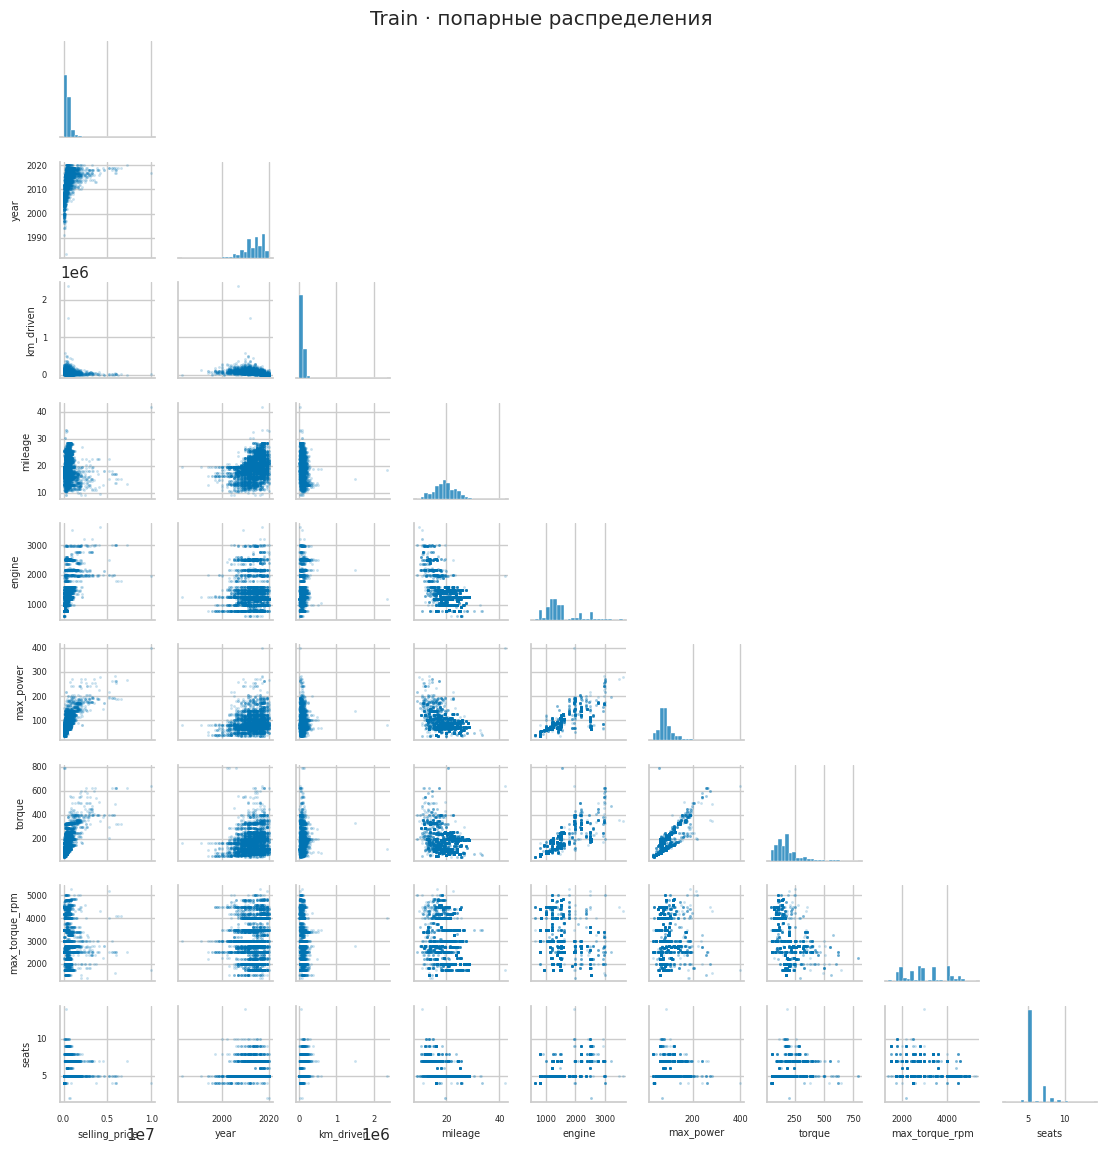

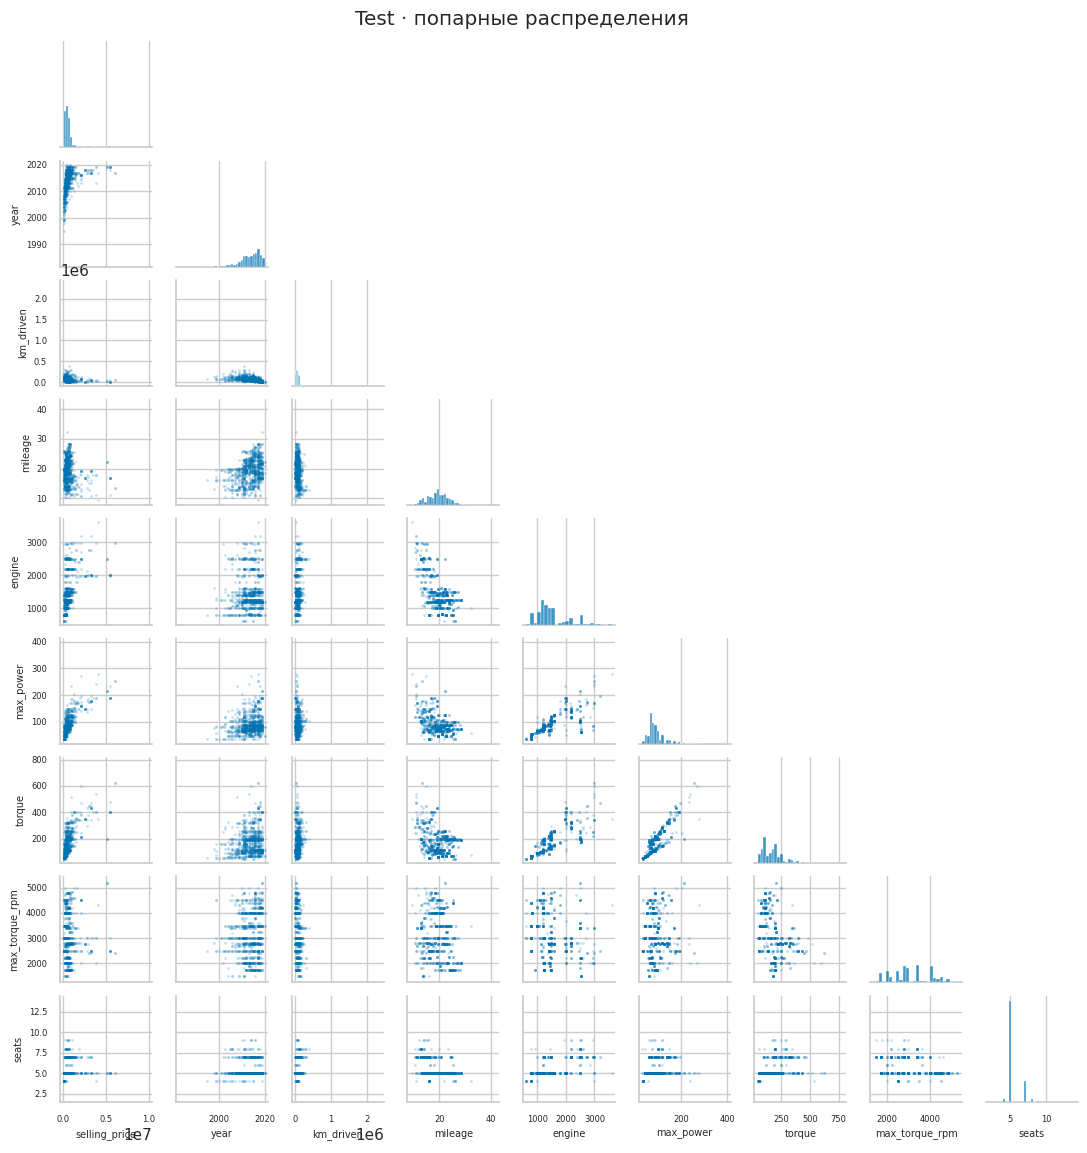

In [14]:
# Одинаковая шкала сохраняет видимым крайний пробег в train.
plot_cols = [TARGET] + NUMERIC
limits = {}
for col in plot_cols:
    values = pd.concat([df_train[col], df_test[col]])
    span = values.max() - values.min()
    limits[col] = (values.min() - 0.04 * span, values.max() + 0.04 * span)
for name, data in [("Train", df_train), ("Test", df_test)]:
    grid = sns.pairplot(data[plot_cols], corner=True, diag_kind="hist", height=1.28,
                        plot_kws={"s": 4, "alpha": 0.22, "linewidth": 0, "rasterized": True},
                        diag_kws={"bins": 24})
    for row, y_col in enumerate(plot_cols):
        for column, x_col in enumerate(plot_cols[:row + 1]):
            ax = grid.axes[row, column]
            ax.set_xlim(limits[x_col])
            if row != column:
                ax.set_ylim(limits[y_col])
            ax.tick_params(labelsize=6)
            ax.xaxis.label.set_size(7)
            ax.yaxis.label.set_size(7)
    grid.figure.suptitle(f"{name} · попарные распределения", y=1.01)
    plt.show()

У дорогих машин чаще выше мощность и крутящий момент. Мощность растёт вместе с объёмом двигателя. Для года видны вертикальные полосы и рост верхней границы цены у более новых машин. В тесте направления связей и основное скопление точек похожи, а редких крайних значений цены и пробега меньше. Линейная связь описывает только часть рисунка.

### **Задание 9 (0.2 балла)**

Итак, вы выдвинули гипотезы о наличии связи. Теперь давайте оценим эту связь в числах.

**Задание:**
- [x] Получите значения коэффициента корреляции Пирсона для тренировочного набора данных при помощи `DataFrame.corr()`
- [x] По полученным корреляциям постройте тепловую карту (`heatmap` из библиотеки seaborn)

,selling_price,year,km_driven,mileage,engine,max_power,torque,max_torque_rpm,seats
selling_price,1.000,0.427,-0.165,-0.103,0.448,0.694,0.625,-0.090,0.150
year,0.427,1.000,-0.369,0.349,0.003,0.157,0.129,0.058,0.041
km_driven,-0.165,-0.369,1.000,-0.191,0.230,0.025,0.133,-0.219,0.192
mileage,-0.103,0.349,-0.191,1.000,-0.586,-0.385,-0.248,-0.187,-0.475
engine,0.448,0.003,0.230,-0.586,1.000,0.682,0.742,-0.260,0.652
max_power,0.694,0.157,0.025,-0.385,0.682,1.000,0.837,-0.023,0.244
torque,0.625,0.129,0.133,-0.248,0.742,0.837,1.000,-0.447,0.374
max_torque_rpm,-0.090,0.058,-0.219,-0.187,-0.260,-0.023,-0.447,1.000,-0.221
seats,0.150,0.041,0.192,-0.475,0.652,0.244,0.374,-0.221,1.000


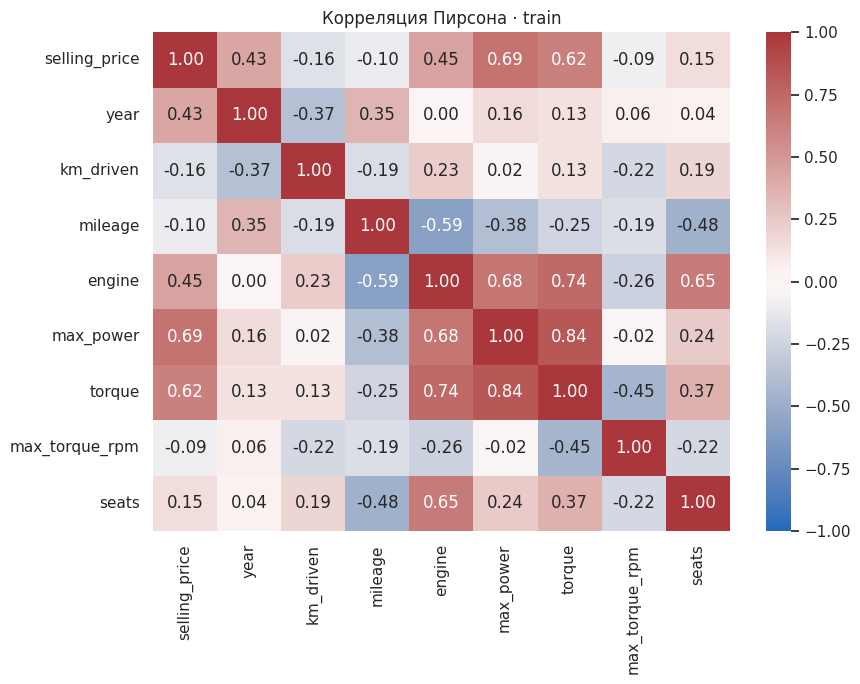

In [15]:
pearson = df_train[plot_cols].corr()
display(pearson)
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(pearson, annot=True, fmt=".2f", center=0, vmin=-1, vmax=1, cmap="vlag", ax=ax)
ax.set_title("Корреляция Пирсона · train")
plt.tight_layout()
plt.show()

- [x] Ответьте на вопросы:
 - Какие 2 признака наименее скоррелированы между собой?
 - Между какими наблюдается довольно сильная положительная линейная зависимость?
 - Правильно ли, опираясь на данные, утверждать, что чем меньше год, тем, скорее всего, больше километров проехала машина к дате продажи?
 - Изучите типы корреляций в `DataFrame.corr()`. Какую вы использовали по умолчанию?

Ближе всего к нулю коэффициент года и объёма двигателя (0,003). Между мощностью и моментом он равен 0,837, между объёмом и моментом — 0,742. Год и пробег имеют умеренную отрицательную связь (−0,369), то есть более ранний год в среднем сопутствует большему пробегу. По одной машине однозначного вывода сделать нельзя. По умолчанию `corr()` использует Пирсона, также доступны Спирмен, Кендалл и пользовательская функция.

### **Задание 10 (0.35 балла)**

По умолчанию `DataFrame.corr` возвращает корреляцию Пирсона, говорящую о линейной взаимосвязи. Но зависимости существуют не только линейные! В этой задаче, попробуйте другие способы вычисления корреляций.

- [x] Реализуйте корреляцию Спирмена/Кендалла (на выбор) без использования библиотек (можно пользоваться только `numpy`). Сравните результаты вычисления с библиотечной реализацией
- [x] Сделайте выводы


Постройте матрицу корреляции [phik](https://pypi.org/project/phik/)
- [x] Проинтерпретируйте результаты

,selling_price,year,km_driven,mileage,engine,max_power,torque,max_torque_rpm,seats
selling_price,1.000,0.707,-0.296,0.026,0.464,0.612,0.592,-0.128,0.318
year,0.707,1.000,-0.570,0.346,-0.038,0.166,0.111,0.077,0.048
km_driven,-0.296,-0.570,1.000,-0.200,0.305,0.041,0.242,-0.322,0.195
mileage,0.026,0.346,-0.200,1.000,-0.432,-0.311,-0.155,-0.176,-0.440
engine,0.464,-0.038,0.305,-0.432,1.000,0.714,0.840,-0.374,0.528
max_power,0.612,0.166,0.041,-0.311,0.714,1.000,0.781,-0.026,0.305
torque,0.592,0.111,0.242,-0.155,0.840,0.781,1.000,-0.533,0.438
max_torque_rpm,-0.128,0.077,-0.322,-0.176,-0.374,-0.026,-0.533,1.000,-0.204
seats,0.318,0.048,0.195,-0.440,0.528,0.305,0.438,-0.204,1.000


Максимальная абсолютная разница: 2.220446049250313e-16


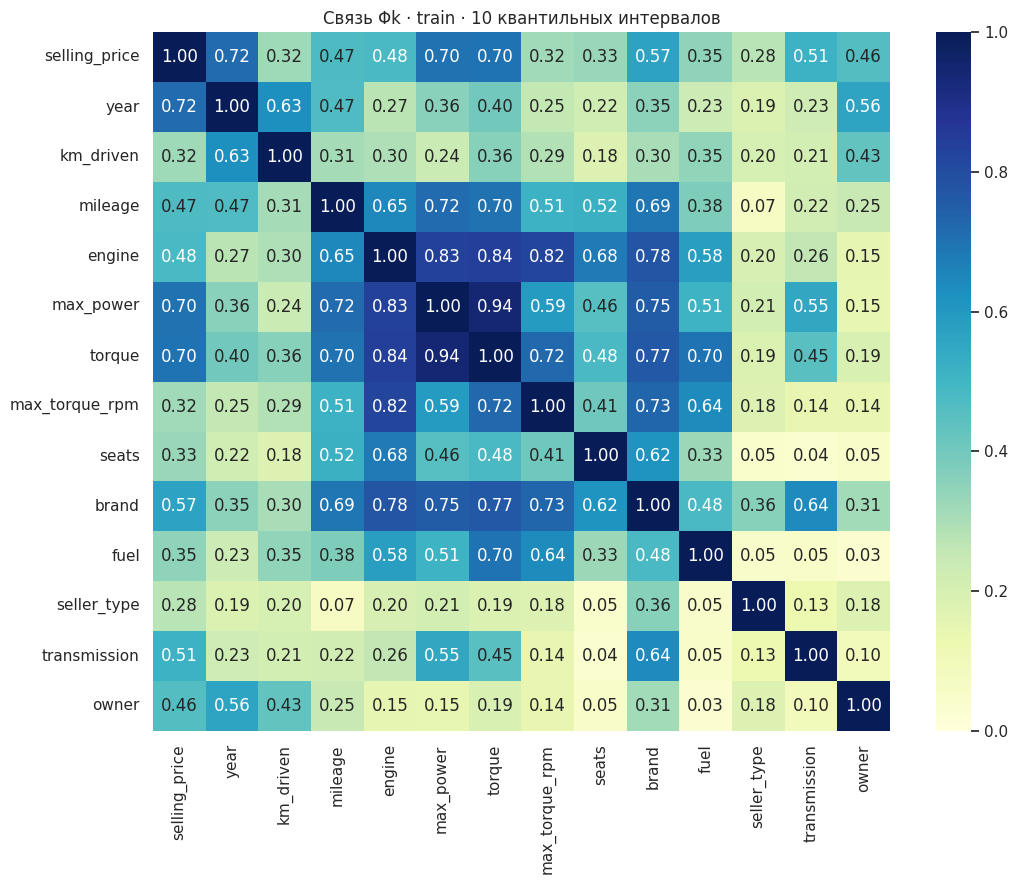

In [16]:
def average_ranks(values):
    # Совпадающие значения получают среднее порядковых номеров, начиная с 1.
    values = np.asarray(values)
    _, inverse, counts = np.unique(values, return_inverse=True, return_counts=True)
    last = np.cumsum(counts)
    return ((last + (last - counts + 1)) / 2)[inverse]

def spearman_numpy(values):
    ranks = np.column_stack([average_ranks(col) for col in np.asarray(values).T])
    centered = ranks - ranks.mean(axis=0)
    norms = np.sqrt((centered ** 2).sum(axis=0))
    with np.errstate(divide="ignore", invalid="ignore"):
        return (centered.T @ centered) / np.outer(norms, norms)

spearman = pd.DataFrame(spearman_numpy(df_train[plot_cols]), index=plot_cols, columns=plot_cols)
reference = df_train[plot_cols].corr(method="spearman")
np.testing.assert_allclose(spearman, reference, atol=1e-12)
display(spearman)
print("Максимальная абсолютная разница:", np.abs(spearman - reference).to_numpy().max())

mixed = pd.concat([df_train[plot_cols], feature_frame(train_unique, "brand")[CATEGORIES]], axis=1)
phi = mixed.phik_matrix(interval_cols=[c for c in plot_cols if c != "seats"],
                        bins=10, quantile=True, njobs=1)
fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(phi, annot=True, fmt=".2f", cmap="YlGnBu", vmin=0, vmax=1, ax=ax)
ax.set_title("Связь Φk · train · 10 квантильных интервалов")
plt.tight_layout()
plt.show()

Ранговый коэффициент для года и цены около 0,707, тогда как линейный коэффициент около 0,427. Порядок цен согласован с годом лучше, чем прямая на исходной шкале. При равенстве рангов ручной расчёт совпал с pandas до машинной точности. Φk улавливает и немонотонную связь, позволяет сравнивать категории с числами. Для цены Φk около 0,72 с годом, 0,70 с мощностью и 0,57 с маркой. У Φk нет знака, а результат зависит от разбиения чисел на интервалы. Ни одна из этих оценок сама по себе не устанавливает причинность.

### **Задание 11 (0.1 балла)**

Если вам кажется, что мы не попросили вас нарисовать какие-то очень важные зависимости, нарисуйте их **и поясните.**

- [x] Постройте хотя бы одну дополнительную визуализацию и объясните, что она показывает и почему это важно.

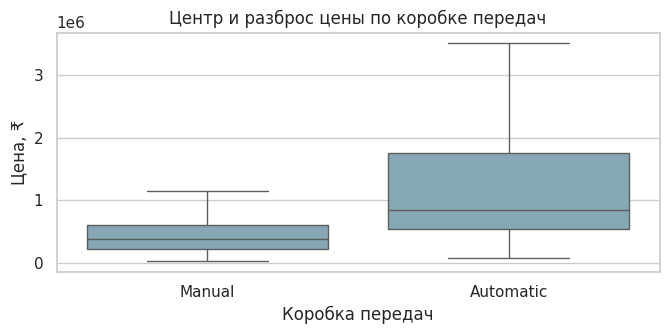

,size,median
transmission,,
Automatic,504,"850,000.000"
Manual,5336,"386,500.000"


In [17]:
fig, ax = plt.subplots(figsize=(7, 3.5))
sns.boxplot(data=df_train, x="transmission", y=TARGET, order=["Manual", "Automatic"], ax=ax,
            color="#7eabbc", showfliers=False)
ax.set(xlabel="Коробка передач", ylabel="Цена, ₹", title="Центр и разброс цены по коробке передач")
plt.tight_layout()
plt.show()
display(df_train.groupby("transmission")[TARGET].agg(["size", "median"]))

Медиана цены у автоматов 850 000 ₹, у машин с механикой — 386 500 ₹. Это обосновывает включение трансмиссии в модель. Величину разницы могут также объяснять марка, мощность и возраст. На графике скрыты отдельные выбросы для читаемости, все цены участвуют в расчётах.

# **Часть 2 (1.4 балла) | Модель только на вещественных признаках**

В этой части вам предстоит обучить модель только на вещественных признаках. Почему только на них?

Чем больше признаковое пространство — тем сложнее модель. А чем модель проще — тем лучше для скорости работы и интерпретации признаков.

За задания этой части вы можете набрать 1.4 балла.

### **Задание 12 (0.05 балла)**

Сделайте тренировочный и тестовый наборы. Они уже даны, достаточно просто отделить целевой признак. Перед разбиением создайте копию датафрейма, который будет хранить только вещественные признаки и используйте его (то есть категориальные столбцы (все, кроме seats) необходимо удалить).

В переменные y_train и y_test запишите значения целевых переменных. Используйте уже имеющиеся данные train и test. Если считаете уместным применить какую-то более хитрую технику разбиения — примените, но опишите, зачем.

In [18]:
numeric_train = df_train[[TARGET] + NUMERIC].copy()
y_train = numeric_train.pop(TARGET)
X_train = numeric_train

In [19]:
units = ["год", "км", "км/л или км/кг", "см³", "bhp", "Н·м", "об/мин", "места"]
display(pd.DataFrame({"единица": units, "минимум train": X_train.min(),
                      "максимум train": X_train.max()}, index=NUMERIC))

,единица,минимум train,максимум train
year,год,"1,983.000","2,020.000"
km_driven,км,1.000,"2,360,457.000"
mileage,км/л или км/кг,9.000,42.000
engine,см³,624.000,"3,604.000"
max_power,bhp,32.800,400.000
torque,Н·м,47.072,789.000
max_torque_rpm,об/мин,"1,400.000","5,300.000"
seats,места,2.000,14.000


In [20]:
numeric_test = df_test[[TARGET] + NUMERIC].copy()
y_test = numeric_test.pop(TARGET)
X_test = numeric_test
assert X_train.columns.equals(X_test.columns) and TARGET not in X_train

### **Задание 13 (0.2 балла)**

Построим нашу первую модель!
- [x] Обучите классическую линейную регрессию с дефолтными параметрами. Посчитайте $R^2$ и $MSE$ для трейна и для теста.
- [x] Сделайте выводы по значениям метрик качества.

**Примечание:**

Здесь и далее $R^2$ и $MSE$ для трейна и для теста выводите везде, где требуется обучать модели, даже если в явном виде этого не просят. Иначе непонятно, как понять, насколько успешны наши эксперименты.

In [21]:
predictions = {}
scores = {}

def record(name, pred_train, pred_test):
    predictions[name] = (np.asarray(pred_train), np.asarray(pred_test))
    scores[name] = {
        "R² train": r2_score(y_train, pred_train),
        "MSE train, ₹²": mean_squared_error(y_train, pred_train),
        "R² test": r2_score(y_test, pred_test),
        "MSE test, ₹²": mean_squared_error(y_test, pred_test),
    }
    return pd.DataFrame([scores[name]], index=[name])

ols = LinearRegression().fit(X_train, y_train)
display(record("МНК", ols.predict(X_train), ols.predict(X_test)))
print(f"RMSE на тесте: {scores['МНК']['MSE test, ₹²'] ** 0.5:,.0f} ₹")

,R² train,"MSE train, ₹²",R² test,"MSE test, ₹²"
МНК,0.604,"113,613,938,283.467",0.601,"229,627,244,111.410"


RMSE на тесте: 479,194 ₹


На восьми числовых признаках обучающий R² равен 0,604, тестовый — 0,601. Обе оценки близки, но RMSE на тесте достигает 479 194 ₹. MSE измеряется в ₹² и особенно чувствительна к ошибкам на дорогих автомобилях. В этом примере похожие R² на двух выборках сочетаются с двукратной разницей в MSE из-за разного разброса цен.

### **Задание 14 (0.25 балла)**

**Шаг 1 (0.15 балла)**
- [x] Реализуйте $R^2$ руками. Приведите формулу $R^2$ и объясните каждую компоненту метрики

In [22]:
def r2_manual(y_true, y_pred):
    actual, predicted = np.asarray(y_true, dtype=float), np.asarray(y_pred, dtype=float)
    residual_ss = np.sum((actual - predicted) ** 2)
    total_ss = np.sum((actual - actual.mean()) ** 2)
    if total_ss == 0:
        return float(residual_ss == 0)  # Как force_finite=True у sklearn.
    return 1 - residual_ss / total_ss

for split, y, p in zip(["train", "test"], [y_train, y_test], predictions["МНК"]):
    np.testing.assert_allclose(r2_manual(y, p), r2_score(y, p))
    print(f"{split}: R² = {r2_manual(y, p):.5f}")

train: R² = 0.60363
test: R² = 0.60053


$$R^2=1-\frac{\sum_i(y_i-\hat y_i)^2}{\sum_i(y_i-\bar y)^2}.$$

$y_i$ — цена продажи, $\hat y_i$ — прогноз, $\bar y$ — среднее фактических цен оцениваемой выборки. Числитель суммирует квадраты ошибок модели, знаменатель — ошибки константного прогноза средним. Единица означает точное совпадение, ноль соответствует ошибке такого среднего, отрицательное значение возможно при ещё большей ошибке.

**Шаг 2 (0.1 балла)**

- [x] Реализуйте [$\text{adjusted}-R^2$](https://en.wikipedia.org/wiki/Coefficient_of_determination).
- [x] Объясните, когда применяется $\text{adjusted}-R^2$?

In [23]:
def adjusted_r2(y_true, y_pred, p):
    n = len(y_true)
    if n <= p + 1:
        raise ValueError("Для adjusted R² нужно n > p + 1")
    return 1 - (1 - r2_manual(y_true, y_pred)) * (n - 1) / (n - p - 1)

for split, y, p in zip(["train", "test"], [y_train, y_test], predictions["МНК"]):
    print(f"{split}: adjusted R² = {adjusted_r2(y, p, X_train.shape[1]):.5f}")

train: adjusted R² = 0.60309
test: adjusted R² = 0.59730


$$R^2_{\mathrm{adj}}=1-(1-R^2)\frac{n-1}{n-p-1}.$$

$n$ — число объектов, $p$ — число регрессоров без свободного члена. На одной обучающей выборке обычный R² у вложенных МНК-моделей не убывает при добавлении признаков. Поправка помогает сравнить модели разной размерности и снижается, если дополнительный регрессор мало уменьшил ошибку. Для прогноза на новых данных используем отложенную оценку.

### **Задание 15 (0.05 балла)**

Всегда есть место совершенству. Поэтому давайте попробуем улучшить модель при помощи стандартизации признаков.

- [x] Стандартизируйте значения в тренировочных и тестовых данных. Стандартизатор **обучайте только на `train`**.

In [24]:
scaler = StandardScaler().fit(X_train)
X_train_std = pd.DataFrame(scaler.transform(X_train), columns=NUMERIC)
X_test_std = pd.DataFrame(scaler.transform(X_test), columns=NUMERIC)
scaled_ols = LinearRegression().fit(X_train_std, y_train)
display(record("МНК + масштаб", scaled_ols.predict(X_train_std), scaled_ols.predict(X_test_std)))
np.testing.assert_allclose(predictions["МНК"][1], predictions["МНК + масштаб"][1], atol=1e-5)

,R² train,"MSE train, ₹²",R² test,"MSE test, ₹²"
МНК + масштаб,0.604,"113,613,938,283.467",0.601,"229,627,244,111.409"


### **Задание 16 (0.1 балла)**

Хотя стандартизация не помогла сильно прибавить в качестве, она открыла возможность интерпретировать важность признаков в модели. Правило интерпретации такое:

Чем больше коэффициент $\beta_i$ по модулю, тем важнее признак.

**Ответьте на вопрос:**

- [x] Какой признак оказался наиболее информативным в предсказании цены?

In [25]:
weights = pd.Series(scaled_ols.coef_, index=NUMERIC, name="₹ за 1 σ")
display(weights.sort_values(key=abs, ascending=False))
strongest = weights.abs().idxmax()
print(f"Максимум по модулю у {strongest}: {weights[strongest]:,.0f} ₹ за одно σ при фиксированных остальных признаках.")

max_power        305,721.631
year             164,906.156
km_driven        -50,199.372
max_torque_rpm   -49,152.431
torque            41,157.142
seats            -31,466.660
engine            12,901.802
mileage          -11,218.761
Name: ₹ за 1 σ, dtype: float64

Максимум по модулю у max_power: 305,722 ₹ за одно σ при фиксированных остальных признаках.


Такое ранжирование относится к конкретной линейной модели. У связанных признаков, например мощности и момента, вес может перераспределяться между ними при изменении набора регрессоров.

### **Задание 17 (0.2 балла)**

Попробуем улучшить нашу модель с помощью применения регуляризации. Для этого воспользуемся `Lasso` регрессией.  Кроме того, попробуйте использовать её теоретическое свойство отбора признаков, за счет зануления незначимых коэффициентов.

**Задание:**

- [x] Обучите Lasso регрессию на тренировочном наборе данных со стандартизованными признаками. Оцените её качество
- [x] Проверьте, занулила ли L1-регуляризация с параметрами по умолчанию какие-нибудь веса? Предположите почему.

In [26]:
default_lasso = Lasso().fit(X_train_std, y_train)
display(record("Lasso по умолчанию", default_lasso.predict(X_train_std), default_lasso.predict(X_test_std)))
display(pd.Series(default_lasso.coef_, index=NUMERIC, name="коэффициент"))
print("Занулено:", np.count_nonzero(default_lasso.coef_ == 0), "из", len(NUMERIC))

,R² train,"MSE train, ₹²",R² test,"MSE test, ₹²"
Lasso по умолчанию,0.604,"113,613,938,298.785",0.601,"229,627,987,976.835"


year             164,903.577
km_driven        -50,198.412
mileage          -11,214.794
engine            12,899.792
max_power        305,722.543
torque            41,157.675
max_torque_rpm   -49,149.634
seats            -31,462.346
Name: коэффициент, dtype: float64

Занулено: 0 из 8


При α = 1 Lasso сохраняет все восемь коэффициентов. Стандартизация уравняла масштабы признаков, а цена осталась в рупиях. Штраф единичного размера мал по сравнению с выигрышем в квадратичной ошибке от этих регрессоров.

### **Задание 18. Финальный рывок (0.3 балла)**

До этого мы с вами использовали `train` для обучения и `test` для прогнозирования. Но у нас есть ещё одна задача — подобрать оптимальные параметры модели. Для этого используем кросс-валидацию, описанную на семинарах.

Кроме того, выжмем максимум из модификаций регрессии. Построим `ElasticNet`. И сделаем всё по порядку.

**Ваша задача 1:**

- [x] Перебором по сетке (с 10 фолдами) подберите оптимальные параметры для Lasso-регрессии. Вам пригодится класс [GridSearchCV](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html).
- [x] Ответьте на вопросы:
 - Сколько грид-сёрчу пришлось обучать моделей?
 - Что значит каждый параметр `param_grid`, который вы заполняли для `GridSearch`? Опишите каждый
 - Какой коэффициент регуляризации у лучшей из перебранных моделей? Занулились ли какие-нибудь из весов при такой регуляризации?

In [27]:
# В CV передаём признаки ДО подстановки медиан. Imputer и scaler входят в pipeline.
X_cv, Xt_cv = parsed_train[NUMERIC], parsed_test[NUMERIC]

def search_numeric(estimator, grid, label):
    pipeline = Pipeline([("impute", SimpleImputer(strategy="median")),
                         ("scale", StandardScaler()), ("model", estimator)])
    search = GridSearchCV(pipeline, grid, scoring="r2", cv=cv, error_score="raise")
    search.fit(X_cv, y_train)
    display(record(label, search.predict(X_cv), search.predict(Xt_cv)))
    n_fits = len(search.cv_results_["params"]) * search.n_splits_
    print(f"Обучений на фолдах: {n_fits}; с финальным refit: {n_fits + 1}.")
    print(f"Лучшие параметры: {search.best_params_}; среднее R² на фолдах: {search.best_score_:.4f}")
    coef = search.best_estimator_.named_steps["model"].coef_
    print("Нулевые веса:", [name for name, w in zip(NUMERIC, coef) if w == 0])
    return search

lasso_search = search_numeric(
    Lasso(max_iter=10000), {"model__alpha": [1, 100, 1000, 10000, 50000, 100000]}, "Lasso CV"
)

,R² train,"MSE train, ₹²",R² test,"MSE test, ₹²"
Lasso CV,0.601,"114,338,709,259.735",0.587,"237,534,113,349.094"


Обучений на фолдах: 60; с финальным refit: 61.
Лучшие параметры: {'model__alpha': 10000}; среднее R² на фолдах: 0.5992
Нулевые веса: ['mileage', 'engine']


Параметр `model__alpha` умножает L1-штраф. Десять фолдов для шести значений потребовали 60 обучений плюс одно на всём train. Лучшее среднее R² получено при α = 10 000. Веса `mileage` и `engine` стали нулевыми. Критерий на фолдах предпочёл более простую модель, хотя на отдельном тесте её R² снизился до 0,587.

**Ваша задача 2:**

- [x] Перебором по сетке (с 10 фолдами) подберите оптимальные параметры для [ElasticNet](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.ElasticNet.html) регрессии.
- [x] Ответьте на вопросы:
 - Сколько грид-сёрчу пришлось обучать моделей?
 - Какие гиперпараметры соответствуют лучшей (по выбранной метрике качества) из перебранных моделей?

In [28]:
elastic_search = search_numeric(
    ElasticNet(max_iter=10000),
    {"model__alpha": [0.001, 0.01, 0.1, 1, 100, 1000],
     "model__l1_ratio": [0.1, 0.5, 0.9, 0.99]}, "ElasticNet CV",
)

,R² train,"MSE train, ₹²",R² test,"MSE test, ₹²"
ElasticNet CV,0.603,"113,661,223,928.097",0.598,"231,088,251,358.884"


Обучений на фолдах: 240; с финальным refit: 241.
Лучшие параметры: {'model__alpha': 1, 'model__l1_ratio': 0.99}; среднее R² на фолдах: 0.5994
Нулевые веса: []


Параметр α задаёт общую силу регуляризации, а `l1_ratio` — долю L1 в смеси L1 и L2. Проверены 24 сочетания на 10 фолдах, то есть 240 обучений и ещё одно на всём train. Лучший вариант имеет α = 1 и `l1_ratio` = 0,99. Его тестовый R² 0,598 близок к числовой МНК.

### **Задание 19 (0.25 балла)**

Итак, вы обучили все варианты регуляризаций, доступные в sklearn, но не все, что мы обсудили на занятии! Следующее задание — о забытой $L0$-регуляризации.

Задача линейной регрессии с $L0$-регуляризацией:

$$\min_{w}\; \frac{1}{n}\|y - Xw\|_2^2 + \lambda \|w\|_0, \qquad \|w\|_0 = \#\{j : w_j \neq 0\}.$$

Штраф $\|w\|_0$ разрывный и невыпуклый, поэтому градиентным спуском «в лоб» задачу не решить. **Выберите один** из способов (или предложите свой и обоснуйте его):

1. **Полный перебор подмножеств (best subset selection).** Для каждого подмножества признаков $S$ обучите МНК только на признаках из $S$ (веса $\hat w_S$) и выберите
$$S^* = \arg\min_{S}\; \frac{1}{n}\|y - X_S \hat w_S\|_2^2 + \lambda |S|.$$
Перебор $2^d$ подмножеств реален при небольшом числе признаков $d$ (у нас вещественных признаков меньше десяти).

2. **Жадный отбор (forward / backward stepwise).** Начните с пустого (полного) набора признаков и на каждом шаге добавляйте (удаляйте) тот признак, который сильнее всего уменьшает $\frac{1}{n}\|y - X_S \hat w_S\|_2^2 + \lambda |S|$. Остановитесь, когда функционал перестанет уменьшаться.

3. **Iterative Hard Thresholding (проксимальный градиентный спуск).** Сделайте шаг градиентного спуска по MSE с шагом $\eta$, затем занулите малые веса:
$$z = w^{(t)} - \eta\, \nabla_w \tfrac{1}{n}\|y - Xw^{(t)}\|_2^2, \qquad w^{(t+1)}_j = z_j \cdot \mathbb{1}\left[|z_j| > \sqrt{2\eta\lambda}\right].$$

4. **Стохастические «ворота» с hard concrete распределением** ([Louizos et al., 2018](https://arxiv.org/abs/1712.01312)). Веса параметризуются как $w = \tilde w \odot z$, где $z_j \in [0, 1]$:
$$u_j \sim U(0,1),\quad s_j = \sigma\!\left(\frac{\log u_j - \log(1-u_j) + \log\alpha_j}{\beta}\right),\quad z_j = \min\big(1, \max(0,\, s_j(\zeta-\gamma)+\gamma)\big),$$
а недифференцируемый $\|w\|_0$ заменяется на его матожидание $\sum_j P(z_j \neq 0)$:
$$\min_{\tilde w,\, \log\alpha}\; \mathbb{E}_u\!\left[\frac{1}{n}\|y - X(\tilde w \odot z)\|_2^2\right] + \lambda\sum_{j}\sigma\!\left(\log\alpha_j - \beta\log\frac{-\gamma}{\zeta}\right).$$
Типичные значения: $\beta = \frac{2}{3},\ \gamma = -0.1,\ \zeta = 1.1$. Оптимизируйте градиентным спуском (например, в PyTorch). На инференсе используйте детерминированные ворота $z_j = \min\big(1, \max(0,\, \sigma(\log\alpha_j)(\zeta-\gamma)+\gamma)\big)$.

Для способов 3 и 4 признаки должны быть стандартизованы.

**Ваша задача:**
- [x] Реализуйте модель с $L0$-регуляризацией одним из способов выше.
- [x] Обучите модель при нескольких значениях $\lambda$ и проанализируйте, как меняются число ненулевых весов и качество ($R^2$ и $MSE$ на трейне и тесте).

**Важно:**

Несмотря на то что L0 не реализована в стандартных пакетах, концепция данной регуляризации не является мертвой. Она встречается в статьях и экспериментах.

In [29]:
# МНК даёт минимум ошибки для каждого из 2⁸ наборов. Штраф не затрагивает свободный член.
subsets = []
for k in range(len(NUMERIC) + 1):
    for subset in combinations(NUMERIC, k):
        cols = list(subset)
        if cols:
            inputs = X_train_std[cols]
            model = LinearRegression().fit(inputs, y_train)
        else:
            inputs = X_train_std
            model = DummyRegressor(strategy="mean").fit(inputs, y_train)
        loss = mean_squared_error(y_train, model.predict(inputs))
        subsets.append((cols, model, loss))

l0_rows = []
for penalty in [0, 1e8, 1e9, 1e10, 1e11, 1e12]:
    cols, model, loss = min(subsets, key=lambda s: s[2] + penalty * len(s[0]))
    pt = model.predict(X_train_std[cols] if cols else X_train_std)
    pv = model.predict(X_test_std[cols] if cols else X_test_std)
    label = f"L0 λ={penalty:.0e}"
    record(label, pt, pv)
    l0_rows.append({"λ, ₹²": penalty, "число весов": len(cols), "признаки": ", ".join(cols),
                    **scores[label]})
display(pd.DataFrame(l0_rows))

,"λ, ₹²",число весов,признаки,R² train,"MSE train, ₹²",R² test,"MSE test, ₹²"
0,0.000,8,"year, km_driven, mileage, engine, max_power, t...",0.604,"113,613,938,283.467",0.601,"229,627,244,111.409"
1,"100,000,000.000",6,"year, km_driven, max_power, torque, max_torque...",0.603,"113,744,624,003.654",0.600,"230,170,630,564.467"
2,"1,000,000,000.000",4,"year, km_driven, max_power, max_torque_rpm",0.602,"114,180,233,001.615",0.597,"231,668,272,506.714"
3,"10,000,000,000.000",2,"year, max_power",0.585,"118,915,818,047.717",0.582,"240,343,891,125.368"
4,"100,000,000,000.000",1,max_power,0.481,"148,685,425,707.171",0.513,"279,688,308,729.557"
5,"1,000,000,000,000.000",0,,0.000,"286,638,338,357.887",-0.016,"583,842,339,797.021"


Из 256 подмножеств для каждого λ выбран минимум обучающей MSE со штрафом. При λ = 0 результат совпадает с МНК. При λ = 10⁹ остаются четыре из восьми признаков при тестовом R² 0,597 вместо 0,601. Дальнейшее сокращение до одной мощности снижает R² до 0,513. При λ = 10¹² выбран константный прогноз средним train.

# **Часть 3 (0.5 балла) | Добавляем категориальные фичи**

Попробуем для улучшения модели дать ей больше признаков. Добавим категориальные фичи.

За эту часть можно набрать 0.5 балла.

### **Задание 20 (0.1 балла)**

Проанализируйте столбец `name`. Очевидно, что эта переменная является категориальной, однако категорий в ней много.

- [x] Создайте `X_train_cat` и `X_test_cat` — копии `df_train` и `df_test` без целевой переменной (со всеми признаками, включая категориальные)
- [x] Предобработайте столбец `name`, чтобы избежать его удаления

In [30]:
X_train_cat = df_train.drop(columns=TARGET).copy()
X_test_cat = df_test.drop(columns=TARGET).copy()
for data, raw in [(X_train_cat, train_unique), (X_test_cat, raw_test)]:
    categories = feature_frame(raw, "brand")[CATEGORIES]
    data[CATEGORIES] = categories
    data.drop(columns="name", inplace=True)
print(f"В train было {train_unique.name.nunique()} названий, получилось {X_train_cat.brand.nunique()} марок.")

В train было 1924 названий, получилось 30 марок.


In [31]:
# 14 столбцов после разбиения torque, минус selling_price; name предобработан в один столбец.
# Если из name получилось несколько столбцов — скорректируйте ожидаемую размерность.
assert X_train_cat.shape == (5840, 13)

In [32]:
X_train_cat.describe(include='object')

,fuel,seller_type,transmission,owner,brand
count,5840,5840,5840,5840,5840
unique,4,3,2,5,30
top,diesel,individual,manual,first owner,maruti
freq,3177,5223,5336,3603,1804


### **Задание 21 (0.1 балла)**

- [x] Закодируйте категориальные фичи и ``seats`` методом OneHot-кодирования.

In [33]:
brand_prep = make_preprocessor("brand").fit(X_train_cat)
X_train_ohe = brand_prep.transform(X_train_cat)
X_test_ohe = brand_prep.transform(X_test_cat)
print("После масштабирования чисел и OHE:", X_train_ohe.shape, X_test_ohe.shape)
print("Столбцы мест:", [c for c in brand_prep.get_feature_names_out() if c.startswith("seats_")])
assert X_train_ohe.shape[1] == X_test_ohe.shape[1]

После масштабирования чисел и OHE: (5840, 54) (1000, 54)
Столбцы мест: ['seats_4.0', 'seats_5.0', 'seats_6.0', 'seats_7.0', 'seats_8.0', 'seats_9.0', 'seats_10.0', 'seats_14.0']


### **Задание 22 (0.2 балла)**

OHE — базовый алгоритм преобразования категориальных признаков, но и с ним нужно быть аккуратными.

**Ответьте на вопросы:**


* Как корректно работать с OHE преобразованием?
* Почему мы удаляем один столбец?
* Пусть из категориального признака с $n$ категориями мы получили $n-1$ столбец, из которых $k < n-1$ оказались неважными по весам модели. Корректно ли их удалить?

Словарь категорий строим на train, затем тем же кодировщиком преобразуем test и новые записи. В CV словарь также обучается внутри фолда. Удаление опорного уровня позволяет использовать свободный член и избежать точной линейной зависимости. Коэффициенты уровней интерпретируются относительно опорного. Для Ridge такое удаление необязательно. Неизвестная категория при `handle_unknown="ignore"` кодируется нулями. Удалив ещё k индикаторов, мы приравняем их к опорному уровню. Объединение требует содержательного обоснования и проверки на валидации. Малый вес в одном обучении сам по себе недостаточен.

### **Задание 23 (0.1 балла)**
Повторим то, что делали на прошлом шаге для моделей на вещественных признаках, однако теперь с моделью `Ridge`.


**Ваша задача:**
- [x] Переберите параметр регуляризации `alpha` для гребневой (ridge) регрессии с помощью класса `GridSearchCV`. В качестве параметров при объявлении GridSearchCV кроме модели укажите метрику качества $R^2$. Кроссвалидируйтесь по 10-ти фолдам.
- [x] Ответьте на вопрос: Удалось ли улучшить качество прогнозов?

In [34]:
alpha_grid = [0.1, 1.0, 10.0, 100.0, 1000.0]
candidates = {}

def search_ridge(label, stage, log_price=False):
    train = feature_frame(train_unique, stage)
    test = feature_frame(raw_test, stage)
    estimator = Pipeline([("prep", make_preprocessor(stage)),
                          ("ridge", Ridge(solver="lsqr", tol=1e-6))])
    param = "ridge__alpha"
    if log_price:
        estimator = TransformedTargetRegressor(regressor=estimator, func=np.log, inverse_func=np.exp)
        param = "regressor__" + param
    search = GridSearchCV(estimator, {param: alpha_grid}, scoring="r2", cv=cv, error_score="raise")
    search.fit(train, y_train)
    record(label, search.predict(train), search.predict(test))
    candidates[label] = (search, stage)
    return {"модель": label, "α": search.best_params_[param],
            "R² CV": search.best_score_, **scores[label]}

ridge_rows = [search_ridge("Ridge · марки", "brand")]
display(pd.DataFrame(ridge_rows).set_index("модель"))
print(f"Изменение R² test относительно МНК: {scores['Ridge · марки']['R² test'] - scores['МНК']['R² test']:+.3f}")

,α,R² CV,R² train,"MSE train, ₹²",R² test,"MSE test, ₹²"
модель,,,,,,
Ridge · марки,1.000,0.732,0.774,"64,700,192,944.831",0.784,"124,190,654,928.265"


Изменение R² test относительно МНК: +0.183


Марка, вид топлива, коробка, тип продавца и число мест добавили информацию о сегменте машины. С ними Ridge улучшила тестовый R² относительно числовой МНК. Одинаковый способ подсчёта MSE позволяет проверить размер улучшения в исходной шкале.

# **Часть 4 (0.4 балла) | Feature Engineering**

### **Задание 24 (0.4 балла)**

В этой части домашнего задания вам предлагается проявить свою креативность для улучшения прогноза модели. Любые другие модели, кроме различных форм линейной (или полиномиальной) регрессии, использовать запрещается. А значит, придется работать с признаками

**Что можно попробовать сделать?** (каждый пункт — до 0.2 балла, но не больше 0.4 балла в сумме)

1.   *Сгенерировать новые признаки на основе уже существующих:*
    * посчитать произведения // частные признаков (кажется, что посчитать число "лошадей" на литр объема может быть полезно);
    * имеет смысл обратить внимание на визуализации в части с EDA (к примеру, зависимость цены от года выглядит квадратичной, а не линейной; значит, квадрат года нам, скорее всего, принесет больше пользы)

2.   *Добыть новые признаки:*
    * из названия автомобиля можно извлечь больше информации (например, спарсить инфу о классе автомобиля или каких-то специфических опциях)
    * можно добавить пороговые признаки вроде "владелец третий или больше" и объединить признаки в некоторые осмысленные правила, например "первый или второй владелец и продавец официальный дилер" (подбирать пороги удобно по диаграммам рассеяния)

3.   *Поработать с уже имеющимися:*
    * далеко не факт, что заполнить пропуск медианой было лучшей идеей (как минимум, можно добавить dummy-столбец для модели, сигнализирующий, что раньше на месте медианы был пропуск -- там где он был, конечно); попробуйте другие способы филлинга;
    * мы не анализировали, есть ли в данных выбросы => никак выбросы не обрабатывали; наиболее простым и, тем не менее, довольно полезным вариантом нахождения выбросов могут послужить boxplot'ы для каждого столбца; что делать с выбросами думайте сами :) -- вариантов довольно много
    * мы толком не смотрели на таргет сам по себе; в нем тоже могут быть неожиданности -- стоит хотя бы проверить
    * можно заметить, что некоторые признаки распределены совсем не нормально; возможно их стоит отлогарифмировать

И так далее...

Feel Free to Try!

In [35]:
ridge_rows += [
    search_ridge("Ridge · модель и версия", "names"),
    search_ridge("Ridge · новые признаки", "engineered"),
    search_ridge("Ridge · логарифм цены", "engineered", log_price=True),
]
comparison = pd.DataFrame(ridge_rows).set_index("модель")
display(comparison)
# Выбор до бизнес-метрик и только по фолдам train. У всех одинаковые фолды и сетка.
winner = comparison["R² CV"].idxmax()
chosen_search, chosen_stage = candidates[winner]
print("Для инференса выбрана:", winner)

,α,R² CV,R² train,"MSE train, ₹²",R² test,"MSE test, ₹²"
модель,,,,,,
Ridge · марки,1.000,0.732,0.774,"64,700,192,944.831",0.784,"124,190,654,928.265"
Ridge · модель и версия,1.000,0.804,0.886,"32,544,405,711.738",0.908,"52,679,641,217.664"
Ridge · новые признаки,1.000,0.877,0.929,"20,449,853,343.191",0.935,"37,285,814,897.037"
Ridge · логарифм цены,1.000,0.910,0.944,"16,031,847,495.530",0.945,"31,687,622,888.134"


Для инференса выбрана: Ridge · логарифм цены


Сначала к марке добавлены семейство (два первых слова названия) и полная комплектация. Уровни, встречающиеся менее трёх раз в обучающем фолде, объединены. Затем добавлены квадрат возраста относительно 2020 г., квадрат мощности, произведение возраста и мощности, мощность на литр, `log1p` пробега и число отсутствующих технических полей. Последний вариант обучен на логарифме цены. Экспонента возвращает положительный прогноз в рупиях, а обучение на логарифмах уменьшает влияние крайних цен. Во всех вариантах регрессор остаётся линейным по построенным признакам.

# **Часть 5 | Бизнесовая (0.4 балла)**

### **Задание 25 (0.2 балла)**

В мире бизнеса очень важно давать оценку качества модели понятную бизнесу, поэтому иногда заказчики приходят с кастомными метриками. Попробуем сделать такую для нашей задачи.

**Описание метрики:**

Среди всех предсказанных цен на авто нужно посчитать долю прогнозов, отличающихся от реальных цен на эти авто не более чем на 10% (в одну или другую сторону). Отклонение считается относительно **реальной** цены $y_i$:

$$\text{business\_metrics}(y, \hat y) = \frac{1}{n}\sum_{i=1}^{n} \mathbb{1}\left[\frac{|\hat y_i - y_i|}{y_i} \le 0.1\right]$$

**Ваша задача:**

- [x] Реализуйте метрику `business_metrics`
- [x] Посчитайте метрику для всех обученных моделей и определите, какая лучше всего решает задачу бизнеса

In [36]:
def business_metrics(y_true, y_pred):
    actual = np.asarray(y_true, dtype=float)
    predicted = np.asarray(y_pred, dtype=float)
    if np.any(actual <= 0):
        raise ValueError("Относительная метрика определена для положительных цен")
    # Эквивалентная запись без деления, обе границы включены.
    return np.mean(np.abs(predicted - actual) <= 0.1 * actual)

assert business_metrics([100, 100, 100], [90, 110, 111]) == 2/3
business = pd.DataFrame.from_dict(scores, orient="index")
for label, (pt, pv) in predictions.items():
    business.loc[label, "±10% train"] = business_metrics(y_train, pt)
    business.loc[label, "±10% test"] = business_metrics(y_test, pv)
display(business.sort_values("±10% test", ascending=False))
best_hit = business["±10% test"].idxmax()
print(f"На тесте лидирует {best_hit}: {business.loc[best_hit, '±10% test']:.1%} оценок в допуске.")

,R² train,"MSE train, ₹²",R² test,"MSE test, ₹²",±10% train,±10% test
Ridge · логарифм цены,0.944,"16,031,847,495.530",0.945,"31,687,622,888.134",0.502,0.455
Ridge · новые признаки,0.929,"20,449,853,343.191",0.935,"37,285,814,897.037",0.445,0.423
Ridge · модель и версия,0.886,"32,544,405,711.738",0.908,"52,679,641,217.664",0.404,0.356
Ridge · марки,0.774,"64,700,192,944.831",0.784,"124,190,654,928.265",0.273,0.309
L0 λ=1e+09,0.602,"114,180,233,001.615",0.597,"231,668,272,506.714",0.228,0.250
МНК + масштаб,0.604,"113,613,938,283.467",0.601,"229,627,244,111.409",0.225,0.247
МНК,0.604,"113,613,938,283.467",0.601,"229,627,244,111.410",0.225,0.247
Lasso по умолчанию,0.604,"113,613,938,298.785",0.601,"229,627,987,976.835",0.225,0.247
Lasso CV,0.601,"114,338,709,259.735",0.587,"237,534,113,349.094",0.230,0.247
L0 λ=0e+00,0.604,"113,613,938,283.467",0.601,"229,627,244,111.409",0.225,0.247


На тесте лидирует Ridge · логарифм цены: 45.5% оценок в допуске.


### **Задание 26 (0.2 балла)**

Но у бизнеса не всегда есть идеи и иногда задача на выбор метрики делегируется вам.

**Задание:**

- [x] Придумайте и реализуйте другую кастомную метрику с учетом того, что модель не должна сильно ошибаться в прогнозе, но недопрогноз для модели, согласно мнению бизнеса, хуже, чем перепрогноз.
- [x] Посчитайте метрику для всех обученных моделей и определите, какая лучше всего решает задачу бизнеса

In [37]:
def asymmetric_error(y_true, y_pred):
    actual = np.asarray(y_true, dtype=float)
    if np.any(actual <= 0):
        raise ValueError("Для метрики нужны положительные цены")
    diff = np.asarray(y_pred, dtype=float) - actual
    return np.mean(np.where(diff < 0, -2 * diff, diff) / actual)

np.testing.assert_allclose(asymmetric_error([100, 100], [90, 110]), 0.15)
for label, (pt, pv) in predictions.items():
    business.loc[label, "штраф train"] = asymmetric_error(y_train, pt)
    business.loc[label, "штраф test"] = asymmetric_error(y_test, pv)
display(business.sort_values("штраф test"))
best_cost = business["штраф test"].idxmin()
print(f"Минимальный средний взвешенный относительный штраф на тесте у {best_cost}: "
      f"{business.loc[best_cost, 'штраф test']:.2%}.")

,R² train,"MSE train, ₹²",R² test,"MSE test, ₹²",±10% train,±10% test,штраф train,штраф test
Ridge · логарифм цены,0.944,"16,031,847,495.530",0.945,"31,687,622,888.134",0.502,0.455,0.198,0.217
Ridge · новые признаки,0.929,"20,449,853,343.191",0.935,"37,285,814,897.037",0.445,0.423,0.317,0.361
Ridge · модель и версия,0.886,"32,544,405,711.738",0.908,"52,679,641,217.664",0.404,0.356,0.402,0.453
Ridge · марки,0.774,"64,700,192,944.831",0.784,"124,190,654,928.265",0.273,0.309,0.667,0.651
L0 λ=1e+11,0.481,"148,685,425,707.171",0.513,"279,688,308,729.557",0.133,0.154,0.899,0.900
Lasso CV,0.601,"114,338,709,259.735",0.587,"237,534,113,349.094",0.230,0.247,0.898,0.926
ElasticNet CV,0.603,"113,661,223,928.097",0.598,"231,088,251,358.884",0.224,0.246,0.941,0.959
Lasso по умолчанию,0.604,"113,613,938,298.785",0.601,"229,627,987,976.835",0.225,0.247,0.951,0.971
МНК + масштаб,0.604,"113,613,938,283.467",0.601,"229,627,244,111.409",0.225,0.247,0.951,0.971
L0 λ=0e+00,0.604,"113,613,938,283.467",0.601,"229,627,244,111.409",0.225,0.247,0.951,0.971


Минимальный средний взвешенный относительный штраф на тесте у Ridge · логарифм цены: 21.70%.


Для автомобиля с ценой $y>0$ считаем $(2\max(y-\hat y,0)+\max(\hat y-y,0))/y$ и усредняем по объявлениям. Меньше — лучше. Занижение на 10% стоит 0,20, завышение на 10% — 0,10. Множитель 2 — принятое для эксперимента допущение о затратах бизнеса. В отличие от доли попаданий этот штраф продолжает расти и за пределами допуска.

### Проверка совпадений между выборками

Эта разбивка оценивает, как знакомые описания влияют на метрики. Основной тест по заданию остаётся целиком.

In [38]:
keys_train = pd.util.hash_pandas_object(train_unique[RAW_COLUMNS], index=False)
keys_test = pd.util.hash_pandas_object(raw_test[RAW_COLUMNS], index=False)
overlap = keys_test.isin(keys_train).to_numpy()
pred_test = predictions[winner][1]
slices = []
for label, mask in [("Весь тест", np.ones(len(y_test), dtype=bool)),
                    ("Совпадают все признаки", overlap), ("Новое описание", ~overlap)]:
    actual, predicted = y_test[mask], pred_test[mask]
    slices.append({"срез": label, "n": len(actual), "R²": r2_score(actual, predicted),
                   "RMSE, ₹": mean_squared_error(actual, predicted) ** 0.5,
                   "±10%": business_metrics(actual, predicted),
                   "штраф": asymmetric_error(actual, predicted)})
display(pd.DataFrame(slices).set_index("срез"))

,n,R²,"RMSE, ₹",±10%,штраф
срез,,,,,
Весь тест,1000,0.945,"178,010.176",0.455,0.217
Совпадают все признаки,213,0.951,"291,133.868",0.507,0.190
Новое описание,787,0.908,"131,620.585",0.441,0.224


In [39]:
relative_error = np.abs(pred_test - y_test) / y_test
price_segment = pd.cut(y_test, [0, 250000, 1500000, np.inf], right=False,
                       labels=["< 250 тыс. ₹", "250 тыс. – 1,5 млн ₹", "≥ 1,5 млн ₹"])
segments = pd.DataFrame({"сегмент": price_segment, "ошибка, ₹": np.abs(pred_test - y_test),
                         "в допуске ±10%": relative_error <= 0.1})
display(segments.groupby("сегмент", observed=True).agg(
    n=("ошибка, ₹", "size"), MAE=("ошибка, ₹", "mean"), попадания=("в допуске ±10%", "mean")
))

,n,MAE,попадания
сегмент,,,
< 250 тыс. ₹,230,"29,220.015",0.348
"250 тыс. – 1,5 млн ₹",710,"67,039.410",0.503
"≥ 1,5 млн ₹",60,"493,617.602",0.300


На 787 строках с новым для train описанием R² составил 0,908, доля попаданий — 44,1%. На полном тесте эти оценки выше. При сравнении RMSE между группами важен их разный состав по цене. На машинах от 1,5 млн ₹ средняя абсолютная ошибка почти 494 тыс. ₹, в допуск попали 18 из 60 прогнозов.

# **Часть 6 | Оформление репозитория (2 балла)**

Домашнее задание оформите как репозиторий на GitHub.

---

### Обязательные файлы:

1. **`.ipynb`-ноутбук** со всеми экспериментами (0.5 балла):

   * полный EDA,
   * все шаги препроцессинга,
   * обучение и сравнение моделей,
   * сохранённые output’ы;
   * ноутбук запускается сверху вниз без ошибок.

2. **`.pickle`-файл** (0.5 балла), содержащий:

   * обученную модель (или пайплайн `scaler + model`);
   * параметры скейлинга;
   * любые числовые объекты, необходимые для инференса внутри Streamlit-приложения.

   Файл должен загружаться и делать предсказание на новых объектах.

3. **`.md`-файл с выводами** о проделанной работе (1 балл):

   * что было сделано (краткое описание каждого этапа), какие результаты были получены (метрики + интерпретация), что дало наибольший прирост качества (0.75 балла);
   * что сделать не удалось и почему — это нормально и даже полезно (0.25 балла).


### **За что могут быть сняты баллы:**

* отсутствие `.pickle` с моделью / пайплайном;
* слабая или неполная аналитика в `.md`-файле;
* беспорядок в ноутбуке или неясная логика вычислений.

In [40]:
# Пайплайн принимает исходные столбцы CSV, включая строки с единицами измерения.
serving_model = Pipeline([
    ("features", FunctionTransformer(feature_frame, kw_args={"stage": chosen_stage}, validate=False)),
    ("regression", clone(chosen_search.best_estimator_)),
]).fit(train_unique[RAW_COLUMNS], y_train)
with open("car_price.pickle", "wb") as f:
    pickle.dump(serving_model, f, protocol=5)
# Новый объект pickle после загрузки воспроизводит весь набор тестовых прогнозов.
with open("car_price.pickle", "rb") as f:
    restored = pickle.load(f)
np.testing.assert_allclose(restored.predict(raw_test[RAW_COLUMNS]), pred_test, rtol=1e-10)
print(f"Первая строка test: прогноз {restored.predict(raw_test[RAW_COLUMNS].iloc[:1])[0]:,.0f} ₹.")
display(model_coefficients(restored).sort_values(key=abs, ascending=False).head(10))

Первая строка test: прогноз 306,921 ₹.


variant_honda city 1.3 exi   -0.664
model_family_tata nano       -0.657
brand_bmw                     0.603
brand_mercedes-benz           0.595
model_family_maruti gypsy     0.585
variant_honda city 1.5 exi   -0.520
brand_fiat                   -0.487
brand_audi                    0.449
brand_peugeot                -0.444
brand_tata                   -0.440
Name: coefficient, dtype: float64

# **<font color="green">Часть 7 | Создание интерактивного приложения на Streamlit (3 балла)</font>**

Вам необходимо создать интерактивное приложение на Streamlit (например, `app.py`), которое запускается командой

```bash
streamlit run app.py
```

и опубликовать его в [Streamlit Community Cloud](https://streamlit.io/cloud). Приложение должно:

- показывать основные информативные графики/гистограммы в рамках EDA (0.75 балла);
- на вход запрашивать csv-файл с признаками объектов или запрашивать признаки объекта в окошках для ввода, и применять на поступивших объектах модель из `.pickle`-файла (1 балл);
- визуализировать веса (коэффициенты) обученной модели (0.75 балла).

**Оценка сервиса (0.5 балла).** Дополните `.md`-файл из Части 6 разделом об оценке приложения:

* насколько приложение удобно в использовании;
* что получилось визуализировать хорошо, а что — менее удачно;
* какие ограничения или проблемы вы заметили;
* какие улучшения планируете в следующей итерации.

**Что нужно сдать:** код приложения в репозитории из Части 6 и ссылку на приложение в Streamlit Community Cloud.

**За что могут быть сняты баллы:** приложение не запускается командой выше или ссылка на него не открывается.

Приложение загружает `car_price.pickle` и поддерживает ручной ввод и пакетный прогноз из CSV. Вкладки с анализом и коэффициентами используют обучающие данные и веса сохранённого пайплайна. Команда запуска из этого репозитория — `streamlit run app.py`. Метрики, ограничения и оценка интерфейса собраны в [README](README.md).